# Práctica 5. Puertas cuánticas de un qubit con Qiskit

## Información general

**Asignatura:** Computación cuántica  
**Sesión:** 5  
**Título:** Puertas cuánticas de un qubit   
**Modalidad:** Individual  
**Entorno recomendado:** Jupyter Notebook  
**Bibliotecas:** NumPy, Matplotlib, Qiskit y Qiskit Aer

## Objetivos

En esta práctica vas a trabajar con puertas cuánticas de un qubit desde dos puntos de vista:

- Como matrices aplicadas a vectores de estado.
- Como operaciones dentro de circuitos de Qiskit.

Al finalizar la práctica deberás ser capaz de:

- Definir puertas cuánticas como matrices unitarias.
- Aplicar puertas a estados de un qubit usando NumPy.
- Reproducir las mismas operaciones con Qiskit.
- Obtener el vector de estado resultante con `Statevector`.
- Calcular probabilidades de medida.
- Distinguir puertas que modifican probabilidades de puertas que modifican fase.
- Analizar el efecto del orden de aplicación de las puertas.
- Simular medidas y comparar probabilidades teóricas con conteos experimentales.

## Entrega

Entrega este notebook completado con:

- Código ejecutado.
- Resultados visibles.
- Tablas completadas cuando se soliciten.
- Gráficas generadas.
- Respuestas razonadas en las celdas indicadas.
- Conclusión final.

## 1. Preparación del entorno

Ejecuta la siguiente celda para importar las bibliotecas necesarias.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

SEMILLA = 42

## 2. Parte A. Puertas como matrices

### Ejercicio 1. Estados de la base computacional

Define con NumPy los estados:

$$
|0\rangle =
\begin{pmatrix}
1 \\
0
\end{pmatrix}
$$

$$
|1\rangle =
\begin{pmatrix}
0 \\
1
\end{pmatrix}
$$

Utiliza explícitamente `dtype=complex`.

In [9]:
# TODO: define los estados de la base computacional
ket_0 = np.array([1,0], dtype=complex)
ket_1 = np.array([0,1], dtype=complex)

print("|0> =", ket_0)
print("|1> =", ket_1)

print("Norma de |0>:",  np.linalg.norm(ket_0))
print("Norma de |1>:",  np.linalg.norm(ket_1))

|0> = [1.+0.j 0.+0.j]
|1> = [0.+0.j 1.+0.j]
Norma de |0>: 1.0
Norma de |1>: 1.0


**Responde:**

1. ¿Qué representa cada componente del vector?
2. ¿Por qué la norma debe ser 1?
3. ¿Por qué usamos `dtype=complex`?

Respuesta:

### Ejercicio 2. Definición de puertas básicas

Define con NumPy las matrices de las siguientes puertas:

$$
I =
\begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix}
$$

$$
X =
\begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}
$$

$$
Y =
\begin{pmatrix}
0 & -i \\
i & 0
\end{pmatrix}
$$

$$
Z =
\begin{pmatrix}
1 & 0 \\
0 & -1
\end{pmatrix}
$$

$$
H =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
$$

In [11]:
# TODO: define las matrices de las puertas
I = np.matrix([[1,0],[0,1]], dtype=complex)
X = np.matrix([[0,1],[1,0]], dtype=complex)
Y = np.matrix([[0,-1j],[1j,0]], dtype=complex)
Z = np.matrix([[1,0],[0,-1]], dtype=complex)
H = (1/np.sqrt(2))* np.matrix([[1,1],[1,-1]], dtype=complex)

puertas_basicas = {
    "I": I,
    "X": X,
    "Y": Y,
    "Z": Z,
    "H": H,
}

for nombre, puerta in puertas_basicas.items():
    print(f"{nombre} =")
    print(puerta)
    print()

I =
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]

X =
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

Y =
[[ 0.+0.j -0.-1.j]
 [ 0.+1.j  0.+0.j]]

Z =
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]

H =
[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]



**Responde:**

1. ¿Qué dimensión tiene cada matriz?
2. ¿Por qué una puerta de un qubit se representa con una matriz 2 x 2?
3. ¿Qué diferencia observas entre las puertas X, Y y Z?

Respuesta:

### Ejercicio 3. Comprobación de unitariedad

Implementa una función que compruebe si una matriz es unitaria:

$$
U^\dagger U = I
$$

Recuerda que $U^\dagger$ es la traspuesta conjugada de U.

In [ ]:
def es_unitaria(U, tolerancia=1e-10):
    '''
    Comprueba si una matriz es unitaria.
    '''
    # TODO: convierte U a array complejo
    U = np.array(U,dtype=complex)

    # TODO: comprueba que sea cuadrada
    det_U= 

    # TODO: calcula la matriz identidad del mismo tamaño
    identidad = 

    # TODO: comprueba U^dagger U = I
    return 

In [5]:
# TODO: comprueba la unitariedad de las puertas básicas
for nombre, puerta in puertas_basicas.items():
    print(nombre, es_unitaria(puerta))

I Ellipsis
X Ellipsis
Y Ellipsis
Z Ellipsis
H Ellipsis


Completa la tabla:

| Puerta | ¿Es unitaria? |
|---|---:|
| I |  |
| X |  |
| Y |  |
| Z |  |
| H |  |

**Responde:**

1. ¿Son unitarias todas las puertas anteriores?
2. ¿Qué propiedad del estado garantiza la unitariedad?
3. ¿Por qué una puerta cuántica debe ser reversible?

Respuesta:

## 3. Parte B. Aplicación de puertas con NumPy

### Ejercicio 4. Función para calcular probabilidades

Implementa una función que devuelva las probabilidades de medir 0 y 1 en la base computacional.

In [12]:
def probabilidades(estado):
    '''
    Devuelve las probabilidades de medir 0 y 1.
    '''
    # TODO: convierte el estado a array complejo
    estado = np.array(estado, dtype=complex)

    # TODO: calcula el módulo al cuadrado de cada amplitud
    probs = np.array([np.abs(estado(0))**2,np.abs(estado(1))**2])

    return {
        0: float(probs[0]),
        1: float(probs[1]),
    }

### Ejercicio 5. Aplicar puertas a $|0\rangle$

Aplica las puertas I, X, Y, Z y H al estado $|0\rangle$.

In [7]:
resultados_ket0 = {}

for nombre, puerta in puertas_basicas.items():
    # TODO: aplica la puerta al estado |0>
    estado_final = ...
    resultados_ket0[nombre] = estado_final

    print(f"{nombre}|0> = {estado_final}")
    print("Probabilidades:", probabilidades(estado_final))
    print()

I|0> = Ellipsis


TypeError: 'ellipsis' object is not subscriptable

Completa la tabla:

| Puerta | Estado resultante | Probabilidad de 0 | Probabilidad de 1 |
|---|---|---:|---:|
| I |  |  |  |
| X |  |  |  |
| Y |  |  |  |
| Z |  |  |  |
| H |  |  |  |

**Responde:**

1. ¿Qué puertas cambian las probabilidades al aplicarse sobre $|0\rangle$?
2. ¿Qué puertas no cambian las probabilidades?
3. ¿Qué diferencia hay entre $X|0\rangle$ e $Y|0\rangle$?
4. ¿Se puede distinguir esa diferencia midiendo directamente en la base computacional?

Respuesta:

### Ejercicio 6. Aplicar puertas a $|1\rangle$

Repite el ejercicio anterior aplicando las mismas puertas a $|1\rangle$.

In [ ]:
resultados_ket1 = {}

for nombre, puerta in puertas_basicas.items():
    # TODO: aplica la puerta al estado |1>
    estado_final = ...
    resultados_ket1[nombre] = estado_final

    print(f"{nombre}|1> = {estado_final}")
    print("Probabilidades:", probabilidades(estado_final))
    print()

Completa la tabla:

| Puerta | Estado resultante | Probabilidad de 0 | Probabilidad de 1 |
|---|---|---:|---:|
| I |  |  |  |
| X |  |  |  |
| Y |  |  |  |
| Z |  |  |  |
| H |  |  |  |

**Responde:**

1. ¿Qué resultado produce $X|1\rangle$?
2. ¿Qué resultado produce $Z|1\rangle$?
3. ¿Son físicamente distinguibles $|1\rangle$ y $-|1\rangle$ mediante una medida directa?
4. ¿Qué estado produce $H|1\rangle$?

Respuesta:

### Ejercicio 7. Estados $|+\rangle$ y $|-\rangle$

Define los estados:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

$$
|-\rangle =
\frac{|0\rangle - |1\rangle}{\sqrt{2}}
$$

In [ ]:
# TODO: define |+> y |->
ket_plus = np.array([1/np.sqrt(2), 1/np.sqrt(2)], dtype=complex)
ket_minus = np.array([1/np.sqrt(2), -1/np.sqrt(2)], dtype=complex)

print("|+> =", ket_plus)
print("|-> =", ket_minus)

print("Norma |+>:",  np.linalg.norm(ket_plus))
print("Norma |->:",  np.linalg.norm(ket_minus))

print("Probabilidades |+>:", probabilidades(ket_plus))
print("Probabilidades |->:", probabilidades(ket_minus))

|+> = [0.70710678+0.j 0.70710678+0.j]
|-> = [ 0.70710678+0.j -0.70710678+0.j]
Norma |+>: Ellipsis
Norma |->: Ellipsis


TypeError: 'numpy.ndarray' object is not callable

**Responde:**

1. ¿Tienen las mismas probabilidades en la base computacional?
2. ¿Son el mismo estado?
3. ¿Qué diferencia hay entre ellos?
4. ¿Qué concepto aparece aquí?

Respuesta:

## 4. Parte C. Las mismas puertas con Qiskit

### Ejercicio 8. Puerta X en Qiskit

Crea un circuito de un qubit que aplique una puerta X, dibújalo y obtén su vector de estado.

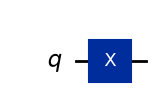

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(1.0)}


In [15]:
# TODO: crea un circuito de un qubit con una puerta X
qc = QuantumCircuit(1)
qc.x(0)

display(qc.draw("mpl"))

estado = Statevector.from_instruction(qc)
display(estado.draw("latex"))
print(estado.probabilities_dict())

**Responde:**

1. ¿Cuál es el estado inicial por defecto en Qiskit?
2. ¿Qué estado se obtiene después de aplicar \(X\)?
3. ¿Coincide con el cálculo hecho con NumPy?

Respuesta:

### Ejercicio 9. Función auxiliar para analizar circuitos

Completa la función `analizar_circuito`.

In [19]:
def analizar_circuito(qc):
    '''
    Dibuja un circuito, muestra su Statevector y devuelve sus probabilidades.
    '''
    # TODO: obtiene el vector de estado
    estado = Statevector.from_circuit(qc)

    display(qc.draw("mpl"))
    display(estado.draw("latex"))

    probs = estado.probabilities()
    print(probs)

    return estado, probs

### Ejercicio 10. Puertas I, X, Y, Z y H en Qiskit

Crea un circuito independiente para cada una de las puertas:

- `id`
- `x`
- `y`
- `z`
- `h`

Todas deben aplicarse sobre el estado inicial $|0\rangle$.

Puerta: X


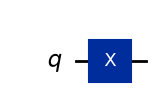

<IPython.core.display.Latex object>

[0. 1.]



In [20]:
circuitos_qiskit = {}

# TODO: crea los circuitos y guárdalos en el diccionario circuitos_qiskit

# Ejemplo:
qc_x = QuantumCircuit(1)
qc_x.x(0)
circuitos_qiskit["X"] = qc_x

for nombre, circuito in circuitos_qiskit.items():
    print("Puerta:", nombre)
    analizar_circuito(circuito)
    print()

**Responde:**

1. ¿Qué puertas producen cambios visibles en las probabilidades?
2. ¿Qué puertas producen cambios de fase?
3. ¿Qué información muestra `Statevector` que no aparece en un histograma?

Respuesta:

## 5. Parte D. Puertas de fase

### Ejercicio 11. Puertas S y T con NumPy

Define con NumPy las puertas:

$$
S =
\begin{pmatrix}
1 & 0 \\
0 & i
\end{pmatrix}
$$

$$
T =
\begin{pmatrix}
1 & 0 \\
0 & e^{i\pi/4}
\end{pmatrix}
$$

In [ ]:
# TODO: define S y T
S = ...
T = ...

print("S =")
print(S)
print()
print("T =")
print(T)

print("S unitaria:", es_unitaria(S))
print("T unitaria:", es_unitaria(T))

In [ ]:
estados_para_fase = {
    "|0>": ket_0,
    "|1>": ket_1,
    "|+>": ket_plus,
}

puertas_fase = {
    "S": S,
    "T": T,
}

for nombre_puerta, puerta in puertas_fase.items():
    for nombre_estado, estado_inicial in estados_para_fase.items():
        # TODO: aplica la puerta al estado inicial
        estado_final = ...
        print(f"{nombre_puerta} sobre {nombre_estado}: {estado_final}")
        print("Probabilidades:", probabilidades(estado_final))
        print()

Completa la tabla:

| Puerta | Estado inicial | Estado final | Probabilidades |
|---|---|---|---|
| S | $\|0\rangle$ |  |  |
| S | $\|1\rangle$ |  |  |
| S | $\|+\rangle$ |  |  |
| T | $\|0\rangle$ |  |  |
| T | $\|1\rangle$ |  |  |
| T | $\|+\rangle$ |  |  |

**Responde:**

1. ¿Cambian las probabilidades al aplicar S o T sobre $|0\rangle$?
2. ¿Cambian las probabilidades al aplicarlas sobre $|1\rangle$?
3. ¿Qué cambia realmente?
4. ¿Por qué es importante la fase relativa?

Respuesta:

### Ejercicio 12. Puertas S y T en Qiskit

Reproduce el ejercicio anterior con Qiskit preparando primero $|+\rangle$ y aplicando después `s` o `t`.

In [ ]:
# TODO: circuito H + S
qc_s = ...
...

# TODO: circuito H + T
qc_t = ...
...

print("Circuito H + S")
estado_s, probs_s = analizar_circuito(qc_s)

print("Circuito H + T")
estado_t, probs_t = analizar_circuito(qc_t)

**Responde:**

1. ¿Coinciden los resultados con NumPy?
2. ¿Qué diferencia hay entre `s` y `t`?
3. ¿Puede una puerta cambiar el estado sin cambiar las probabilidades de medida en la base computacional?

Respuesta:

## 6. Parte E. Fase relativa e interferencia

### Ejercicio 13. Comparación entre $|+\rangle$ y $|-\rangle$

Crea dos circuitos.

Circuito A:

```python
qc_a = QuantumCircuit(1)
qc_a.h(0)
```

Circuito B:

```python
qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.z(0)
```

In [ ]:
# TODO: crea el circuito A
qc_a = QuantumCircuit(1)
qc_a.h(0)

# TODO: crea el circuito B
qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.z(0)

print("Circuito A")
estado_a, probs_a = analizar_circuito(qc_a)

print("Circuito B")
estado_b, probs_b = analizar_circuito(qc_b)

**Responde:**

1. ¿Qué estado prepara el circuito A?
2. ¿Qué estado prepara el circuito B?
3. ¿Tienen las mismas probabilidades?
4. ¿Son el mismo estado?
5. ¿Qué diferencia hay entre ellos?

Respuesta:

### Ejercicio 14. Convertir fase en probabilidad

Añade una puerta H al final de los dos circuitos anteriores.

Circuito A:

```python
qc_a = QuantumCircuit(1)
qc_a.h(0)
qc_a.h(0)
```

Circuito B:

```python
qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.z(0)
qc_b.h(0)
```

In [ ]:
# TODO: circuito A con H final
qc_a_final = QuantumCircuit(1)
qc_a_final.h(0)
qc_a_final.h(0)

# TODO: circuito B con H final
qc_b_final = QuantumCircuit(1)
qc_b_final.h(0)
qc_b_final.z(0)
qc_b_final.h(0)

print("Circuito A final")
estado_a_final, probs_a_final = analizar_circuito(qc_a_final)

print("Circuito B final")
estado_b_final, probs_b_final = analizar_circuito(qc_b_final)

Completa la tabla:

| Circuito | Estado antes de la última H | Estado final | P(0) | P(1) |
|---|---|---|---:|---:|
| A |  |  |  |  |
| B |  |  |  |  |

**Responde:**

1. ¿Qué resultado produce el circuito A?
2. ¿Qué resultado produce el circuito B?
3. ¿Por qué ahora sí aparece una diferencia en las probabilidades?
4. ¿Qué relación tiene esto con la interferencia cuántica?

Respuesta:

## 7. Parte F. Composición y orden de puertas

### Ejercicio 15. Comparación de órdenes

Crea dos circuitos:

Circuito 1:

```python
qc1 = QuantumCircuit(1)
qc1.h(0)
qc1.z(0)
```

Circuito 2:

```python
qc2 = QuantumCircuit(1)
qc2.z(0)
qc2.h(0)
```

In [ ]:
# TODO: crea ambos circuitos
qc1 = QuantumCircuit(1)
qc1.h(0)
qc1.z(0)

qc2 = QuantumCircuit(1)
qc2.z(0)
qc2.h(0)

print("Circuito 1: H y después Z")
estado_1, probs_1 = analizar_circuito(qc1)

print("Circuito 2: Z y después H")
estado_2, probs_2 = analizar_circuito(qc2)

**Responde:**

1. ¿Son iguales los estados finales?
2. ¿Son iguales las probabilidades?
3. ¿Por qué puede ocurrir que los estados sean distintos pero las probabilidades iguales?
4. ¿Importa el orden de aplicación de puertas?
5. ¿Qué significa que dos puertas no conmuten?

Respuesta:

### Ejercicio 16. Comprobación matricial del orden

Calcula con NumPy:

$$
ZH|0\rangle
$$

y:

$$
HZ|0\rangle
$$

In [ ]:
# TODO: calcula ambos estados con NumPy
estado_1_numpy = ...
estado_2_numpy = ...

print("ZH|0> =", estado_1_numpy)
print("HZ|0> =", estado_2_numpy)

**Responde:**

1. ¿Coinciden NumPy y Qiskit?
2. ¿Qué operación se aplica primero en la expresión $ZH|0\rangle$?
3. ¿Cómo se relaciona el orden matricial con el orden visual del circuito?

Respuesta:

## 8. Parte G. Puertas inversas

### Ejercicio 17. Puertas que son su propia inversa

Comprueba con Qiskit que las siguientes puertas aplicadas dos veces devuelven el estado inicial:

- X
- Y
- Z
- H

In [ ]:
puertas_dos_veces = ["x", "y", "z", "h"]

for nombre in puertas_dos_veces:
    qc = QuantumCircuit(1)

    # TODO: aplica dos veces la puerta indicada por nombre
    ...

    print(f"Puerta {nombre.upper()} aplicada dos veces")
    estado, probs = analizar_circuito(qc)
    print()

Completa la tabla:

| Puerta aplicada dos veces | Estado final |
|---|---|
| X |  |
| Y |  |
| Z |  |
| H |  |

**Responde:**

1. ¿Qué tienen en común estas puertas?
2. ¿Qué significa que una puerta sea su propia inversa?
3. ¿Se cumple exactamente o aparece alguna fase global en algún caso?

Respuesta:

### Ejercicio 18. Inversas de S y T

Crea los siguientes circuitos:

```python
qc_s = QuantumCircuit(1)
qc_s.h(0)
qc_s.s(0)
qc_s.sdg(0)
```

```python
qc_t = QuantumCircuit(1)
qc_t.h(0)
qc_t.t(0)
qc_t.tdg(0)
```

In [ ]:
# TODO: circuito con S y su inversa
qc_s_inv = ...
...

# TODO: circuito con T y su inversa
qc_t_inv = ...
...

print("S seguida de Sdg")
estado_s_inv, probs_s_inv = analizar_circuito(qc_s_inv)

print("T seguida de Tdg")
estado_t_inv, probs_t_inv = analizar_circuito(qc_t_inv)

**Responde:**

1. ¿Qué hace `sdg`?
2. ¿Qué hace `tdg`?
3. ¿Por qué el estado final vuelve a coincidir con el estado anterior a aplicar `s` o `t`?
4. ¿Qué relación tiene esto con la reversibilidad?

Respuesta:

## 9. Parte H. Rotaciones

### Ejercicio 19. Rotación $R_y(\theta)$

Crea circuitos que apliquen $R_y(\theta)$ sobre $|0\rangle$ para los siguientes valores:

$$
\theta = 0,\ \frac{\pi}{4},\ \frac{\pi}{2},\ \pi
$$

In [ ]:
angulos = [0, np.pi / 4, np.pi / 2, np.pi]
resultados_ry = []

for theta in angulos:
    qc = QuantumCircuit(1)

    # TODO: aplica ry(theta, 0)
    ...

    estado = Statevector.from_instruction(qc)
    probs = estado.probabilities_dict()

    resultados_ry.append((theta, estado, probs))

    print("theta =", theta)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print(probs)
    print()

Completa la tabla:

| $\theta$ | Estado aproximado | P(0) | P(1) |
|---:|---|---:|---:|
| 0 |  |  |  |
| $\pi/4$ |  |  |  |
| $\pi/2$ |  |  |  |
| $\pi$ |  |  |  |

**Responde:**

1. ¿Qué ocurre cuando aumenta $\theta$?
2. ¿Qué valor de $\theta$ produce una superposición equilibrada?
3. ¿Qué valor de $\theta$ lleva aproximadamente de $|0\rangle$ a $|1\rangle$?
4. ¿Por qué las rotaciones son útiles?

Respuesta:

### Ejercicio 20. Rotación $R_z(\theta)$)

Crea circuitos que preparen primero $|+\rangle$ y después apliquen $R_z(\theta)$:

```python
qc = QuantumCircuit(1)
qc.h(0)
qc.rz(theta, 0)
```

Utiliza:

$$
\theta = 0,\ \frac{\pi}{2},\ \pi
$$

In [ ]:
angulos_rz = [0, np.pi / 2, np.pi]
resultados_rz = []

for theta in angulos_rz:
    qc = QuantumCircuit(1)

    # TODO: prepara |+> y aplica rz(theta, 0)
    ...

    estado = Statevector.from_instruction(qc)
    probs = estado.probabilities_dict()

    resultados_rz.append((theta, estado, probs))

    print("theta =", theta)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print(probs)
    print()

**Responde:**

1. ¿Cambian las probabilidades?
2. ¿Cambia el estado?
3. ¿Qué modifica principalmente $R_z$?
4. ¿Por qué este efecto puede no verse en un histograma de la base computacional?

Respuesta:

## 10. Parte I. Medidas y conteos

### Ejercicio 21. Medir después de aplicar puertas

Crea un circuito que prepare el estado:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

y lo mida con `shots = 1000`.

In [ ]:
shots = 1000

# TODO: crea un circuito con un qubit y un bit clásico
qc_medida = ...

# TODO: prepara |+> y mide
...

display(qc_medida.draw("mpl"))

simulador = AerSimulator(seed_simulator=SEMILLA)
qc_t = transpile(qc_medida, simulador)

resultado = simulador.run(qc_t, shots=shots).result()
conteos = resultado.get_counts()

conteos

**Responde:**

1. ¿Qué resultados esperas obtener?
2. ¿Coinciden exactamente con 500 y 500?
3. ¿Por qué?
4. ¿Qué diferencia hay entre probabilidades teóricas y conteos?

Respuesta:

### Ejercicio 22. Histograma de resultados

Representa los conteos del ejercicio anterior mediante un gráfico de barras.

El gráfico debe incluir:

- Título.
- Etiqueta del eje X.
- Etiqueta del eje Y.
- Valores encima de las barras.

In [ ]:
# TODO: crea un gráfico de barras con los conteos
etiquetas = ...
valores = ...

fig, ax = plt.subplots(figsize=(6, 4))

barras = ax.bar(etiquetas, valores)

# TODO: añade etiquetas, título y valores encima de las barras
...

plt.tight_layout()
plt.show()

**Responde:**

1. ¿Qué representa el histograma?
2. ¿Muestra directamente las amplitudes?
3. ¿Muestra directamente la fase?
4. ¿Qué información se pierde al medir?

Respuesta:

## 11. Reto avanzado

### Ejercicio 23. Distinguir $|+\rangle$ y $|-\rangle$ mediante una operación previa

Sabemos que $|+\rangle$ y $|-\rangle$ producen las mismas probabilidades si se miden directamente en la base computacional.

Diseña un procedimiento con Qiskit para distinguirlos.

Pista: antes de medir, aplica una puerta adecuada.

Debes construir dos circuitos:

1. Uno que prepare $|+\rangle$, aplique la operación elegida y mida.
2. Otro que prepare $|-\rangle$, aplique la operación elegida y mida.

Ejecuta ambos con `shots=1000`.

In [ ]:
# TODO: circuito para preparar |+>, aplicar una operación previa y medir
qc_plus_medida = ...
...

# TODO: circuito para preparar |->, aplicar una operación previa y medir
qc_minus_medida = ...
...

simulador = AerSimulator(seed_simulator=SEMILLA)

qc_plus_t = transpile(qc_plus_medida, simulador)
qc_minus_t = transpile(qc_minus_medida, simulador)

conteos_plus = simulador.run(qc_plus_t, shots=shots).result().get_counts()
conteos_minus = simulador.run(qc_minus_t, shots=shots).result().get_counts()

print("Conteos para |+>:", conteos_plus)
print("Conteos para |->:", conteos_minus)

Completa la tabla:

| Estado inicial | Operación antes de medir | Resultado esperado | Conteos obtenidos |
|---|---|---|---|
| $\|+\rangle$ |  |  |  |
| $\|-\rangle$ |  |  |  |

**Responde:**

1. ¿Qué puerta has utilizado antes de medir?
2. ¿Por qué permite distinguir los dos estados?
3. ¿Qué resultado se obtiene para $|+\rangle$?
4. ¿Qué resultado se obtiene para $|-\rangle$?
5. ¿Qué demuestra este experimento sobre la fase relativa?

Respuesta:

## 12. Pruebas mínimas

Incluye al final del notebook las siguientes pruebas mediante `assert`.

Las pruebas deben ejecutarse sin errores cuando la práctica esté completada correctamente.

In [ ]:
assert np.isclose(np.linalg.norm(ket_0), 1)
assert np.isclose(np.linalg.norm(ket_1), 1)

assert es_unitaria(I)
assert es_unitaria(X)
assert es_unitaria(Y)
assert es_unitaria(Z)
assert es_unitaria(H)
assert es_unitaria(S)
assert es_unitaria(T)

assert np.allclose(X @ ket_0, ket_1)
assert np.allclose(H @ ket_0, ket_plus)
assert np.allclose(H @ H, I)

for estado in [ket_0, ket_1, ket_plus, ket_minus]:
    probs = probabilidades(estado)
    assert np.isclose(sum(probs.values()), 1)

assert sum(conteos.values()) == shots

## 13. Conclusión final

Redacta una conclusión de entre 150 y 250 palabras respondiendo a estas preguntas:

1. ¿Qué es una puerta cuántica de un qubit?
2. ¿Por qué las puertas cuánticas deben ser unitarias?
3. ¿Qué diferencia hay entre una puerta que cambia probabilidades y una puerta que cambia fase?
4. ¿Por qué dos estados distintos pueden producir el mismo histograma?
5. ¿Por qué el orden de las puertas importa?
6. ¿Qué has comprobado al comparar NumPy y Qiskit?

Conclusión: